# TSP (Position-Indexed) → QUBO (Penalty Formulation)

This notebook teaches how to:

1. Define **position-indexed** Traveling Salesman Problem variables.
2. Write a constrained **TSP** model using those variables.
3. Convert constraints into **QUBO penalties** (squared terms).
4. Build the full QUBO energy: **travel cost + penalties**.
5. Work small numeric examples and inspect the resulting QUBO formulation.

---

## Big idea (intuitive)

- We have a set of **cities**.
- The salesman must visit every city exactly once and return to the starting city.
- We model the tour using **positions**:
  
$$
t = 0,1,\dots,n-1
$$

- At each position $t$, exactly one city must be selected.
- Each city must appear exactly once in the tour.
- QUBO requires:
  - **binary variables**
  - a single **unconstrained quadratic objective**
- Therefore, all constraints are absorbed into the objective through quadratic penalty terms.

## 1) Create Instance

In the TSP we only need:

- Travel costs $c_{ij}$

The tour is represented only by the order in which cities are visited.

### Define Number of Cities

In [1]:
# --- User parameters (edit these) ---
n_cities = 4      # total number of cities
seed = 2          # RNG seed for generating example instances

lambdas = {
    "position": 50,   # exactly one city per position
    "visit": 50       # each city visited exactly once
}

The dictionary `lambdas` stores the penalty weights used to enforce the TSP constraints inside the QUBO objective.

In the TSP formulation we only need two constraints:

1. Each tour position must contain exactly one city.
2. Each city must appear exactly once in the tour.

### Random Instance Generator

We generate symmetric TSP instances using random 2D coordinates.

From the coordinates we derive four independent edge-weight matrices:

- Distance
- Time
- Risk
- Cost

Each matrix defines a different TSP instance over the same graph.

In [2]:
import numpy as np

def generate_instance(n_cities, seed=0):
    rng = np.random.default_rng(seed)

    # -------------------------
    # 1) Coordinates
    # -------------------------
    coords = rng.uniform(0, 10, size=(n_cities, 2))

    # Euclidean distances
    dist = np.linalg.norm(
        coords[:, None, :] - coords[None, :, :],
        axis=-1
    )

    distance = np.rint(dist * 10).astype(int)

    # -------------------------
    # 2) Congestion
    # -------------------------
    congestion = rng.uniform(0.8, 2.5, size=(n_cities, n_cities))
    congestion = (congestion + congestion.T) / 2

    time = dist * congestion**2
    time = np.rint(time * 100).astype(int)

    # -------------------------
    # 3) Risk
    # -------------------------
    risk = rng.integers(1, 10, size=(n_cities, n_cities))
    risk = (risk + risk.T) // 2

    # -------------------------
    # 4) Cost
    # -------------------------
    cost = rng.integers(5, 50, size=(n_cities, n_cities))
    cost = (cost + cost.T) // 2

    # -------------------------
    # Remove diagonals
    # -------------------------
    for M in [distance, time, risk, cost]:
        np.fill_diagonal(M, 0)

    return distance, time, risk, cost, coords

# -------------------------
# Example
# -------------------------

dist_matrix, time_matrix, risk_matrix, cost_matrix, coords = (
    generate_instance(n_cities, seed)
)

print("Distance matrix")
print(dist_matrix)

print("\nTime matrix")
print(time_matrix)

print("\nRisk matrix")
print(risk_matrix)

print("\nCost matrix")
print(cost_matrix)

instances = {
    "Distance": dist_matrix,
    "Time": time_matrix,
    "Risk": risk_matrix,
    "Cost": cost_matrix
}

Distance matrix
[[ 0 59 55 25]
 [59  0 67 63]
 [55 67  0 79]
 [25 63 79  0]]

Time matrix
[[   0 1759 2414  379]
 [1759    0 2034 1971]
 [2414 2034    0 2327]
 [ 379 1971 2327    0]]

Risk matrix
[[0 3 8 9]
 [3 0 3 4]
 [8 3 0 3]
 [9 4 3 0]]

Cost matrix
[[ 0 33 29 34]
 [33  0 26 33]
 [29 26  0 22]
 [34 33 22  0]]


### Visualize Graph


We visualize the TSP graph using NetworkX.

Each node represents a city and each edge weight represents the travel cost between two cities.

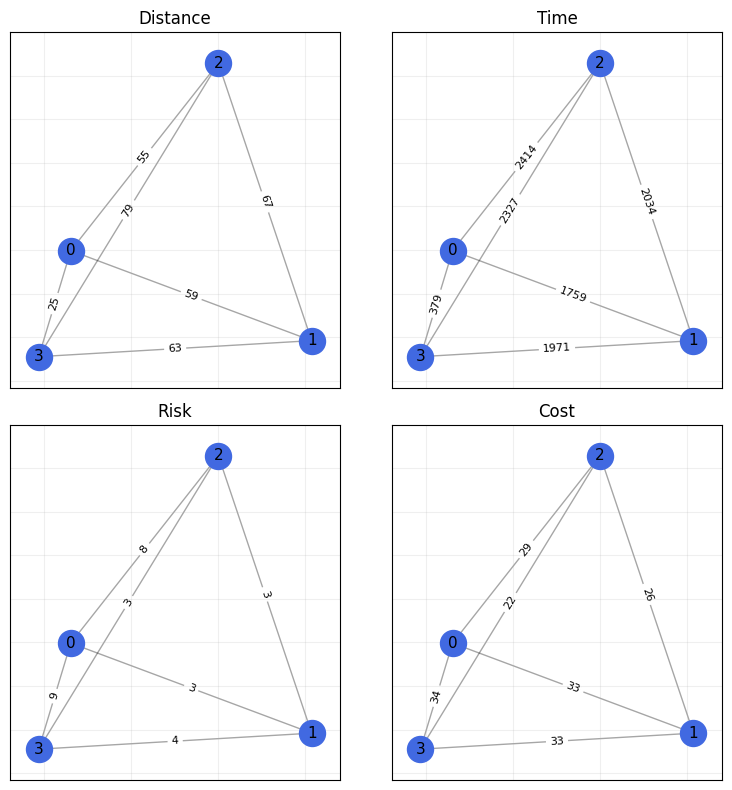

In [3]:
import matplotlib.pyplot as plt
import networkx as nx

def draw_tsp_graph_networkx(coords, cost_matrix, title="TSP graph",
							cost_threshold=None,
							show_weights=True, ax=None):
    coords = np.asarray(coords)
    c = np.asarray(cost_matrix)

    n_nodes = coords.shape[0]

    G = nx.Graph()

    for i in range(n_nodes):
        G.add_node(i, pos=(coords[i, 0], coords[i, 1]))

    for i in range(n_nodes):
        for j in range(i + 1, n_nodes):
            if cost_threshold is None or c[i, j] <= cost_threshold:
                G.add_edge(i, j, weight=int(c[i, j]))

    pos = {i: (coords[i, 0], coords[i, 1]) for i in range(n_nodes)}

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))

    nx.draw_networkx_nodes(G, pos,
                           node_color="royalblue", node_shape="o", node_size=350,
        				   ax=ax)

    nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.0, ax=ax)

    nx.draw_networkx_labels(G, pos, font_size=11, font_color="black", ax=ax)

    if show_weights:
        edge_labels = {(u, v): d["weight"] for u, v, d in G.edges(data=True)}

        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, 
                                     font_size=8, ax=ax)

    ax.set_title(title)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, (name, matrix) in zip(axes.flatten(), instances.items()):
    draw_tsp_graph_networkx(coords, matrix, title=name, ax=ax)

plt.tight_layout()
plt.show()

## 2) Sets and notation

Cities:
$$
C = \{0,\dots,n-1\}
$$

Tour positions:
$$
t \in \{0,\dots,n-1\}
$$

Binary variable:
$$
x_{i,t}=1
\iff
\text{city }i\text{ is visited at position }t
$$

In [4]:
def build_sets(n_cities):

    C = list(range(n_cities))
    T = list(range(n_cities))

    return C, T


C, T = build_sets(n_cities)

print("Cities:", C)
print("Positions:", T)

Cities: [0, 1, 2, 3]
Positions: [0, 1, 2, 3]


## 3) Variable indexing: map $x_{i,t}$ into a single QUBO vector


A QUBO uses one large binary vector $z$.

We map each binary variable
$$
x_{i,t}
$$
to a unique position in that vector.

In [5]:
def variable_indexing(n_cities):

    x_index = {
        (i, t): idx
        for idx, (i, t) in enumerate(
            (i, t)
            for i in range(n_cities)
            for t in range(n_cities)
        )
    }

    return x_index, len(x_index)


x_index, n_vars = variable_indexing(n_cities)

print("Total binary variables:", n_vars)
print("Expected:", n_cities**2)

Total binary variables: 16
Expected: 16


## 4) QUBO construction helpers


We construct an energy:
$$
H(z) = z^T Q z + \text{constant}
$$

We use helper functions to add:

- linear terms $a z_i$
- quadratic terms $b z_i z_j$
- squared penalties
$$
\left(\sum_i a_i z_i + c\right)^2
$$

In [6]:
def add_quadratic(Q, i, j, c):
    Q[min(i, j), max(i, j)] += c

def add_linear(Q, i, c):
    Q[i, i] += c

def add_penalty(Q, terms, const=0, weight=1):
    items = list(terms.items())

    for p, (i, ai) in enumerate(items):
        add_linear(Q, i, weight * (ai**2 + 2*const*ai))

        for j, aj in items[p+1:]:
            add_quadratic(Q, i, j, weight * 2 * ai * aj)

    return weight * const**2

## 5) Build the full QUBO (cost + penalties)


The TSP QUBO contains:

1. Travel cost objective
2. One city per position constraint
3. Each city visited exactly once constraint

In [7]:
def build_qubo(cost_matrix):
    max_cost = np.max(cost_matrix) * n_cities

    lambdas_adjusted = {k: v * max_cost for k, v in lambdas.items()}

    x_index, n_vars = variable_indexing(n_cities)

    Q = np.zeros((n_vars, n_vars))

    const = 0

    # -------------------------
    # 1) Travel cost
    # -------------------------
    for t in range(n_cities):
        t_next = (t + 1) % n_cities

        for i in C:
            for j in C:
                if i == j:
                    continue

                ii = x_index[(i, t)]
                jj = x_index[(j, t_next)]

                add_quadratic(Q, ii, jj, cost_matrix[i, j])

    # -------------------------
    # 2) One city per position
    # -------------------------
    for t in T:
        terms = {x_index[(i, t)]: 1 for i in C}
        const += add_penalty(Q, terms, const=-1,
            				 weight=lambdas_adjusted["position"])

    # -------------------------
    # 3) Each city visited once
    # -------------------------
    for i in C:
        terms = {x_index[(i, t)]: 1 for t in T}

        const += add_penalty(Q, terms, const=-1,
            				 weight=lambdas_adjusted["visit"])

    info = {
        "coords": coords,
        "cost_matrix": cost_matrix,
        "x_index": x_index,
        "n_vars": n_vars,
        "lambdas": lambdas_adjusted
    }

    return Q, const, info


# -------------------------
# Build all QUBOs
# -------------------------
qubo_models = {}

for name, matrix in instances.items():
    Q, const, info = build_qubo(matrix)

    qubo_models[name] = {
        "Q": Q,
        "const": const,
        "info": info
    }

    print(f"\n{name.upper()} QUBO")

    print("Variables:", info["n_vars"])

    print("Constant:", const)

    print("Max |Q| coeff:", np.max(np.abs(Q)))


DISTANCE QUBO
Variables: 16
Constant: 126400
Max |Q| coeff: 31600.0

TIME QUBO
Variables: 16
Constant: 3862400
Max |Q| coeff: 965600.0

RISK QUBO
Variables: 16
Constant: 14400
Max |Q| coeff: 3600.0

COST QUBO
Variables: 16
Constant: 54400
Max |Q| coeff: 13600.0


# 6) Exploring Solutions


Find optimal TSP tours by solving the QUBO formulation.

### Solve by Brute Force


#### Parallel

In [9]:
from itertools import product
from multiprocessing import Pool, cpu_count

from tqdm import tqdm


def solve_chunk(args):
    Q, const, prefix, n = args

    best_val = np.inf
    best_x = []

    for tail in product([0, 1], repeat=n - len(prefix)):
        x = np.array(prefix + tail)

        val = x @ Q @ x + const

        if val < best_val:
            best_val = val
            best_x = [x]

        elif val == best_val:
            best_x.append(x)

    return best_val, best_x


def brute_force_parallel(Q, const=0, k=10):
    n = len(Q)

    args = [
        (Q, const, prefix, n)
        for prefix in product([0, 1], repeat=k)
    ]

    results = []

    with Pool(cpu_count()) as pool:
        for r in tqdm(
            pool.imap_unordered(solve_chunk, args),
            total=len(args),
            desc="Brute force"
        ):
            results.append(r)

    best_val = np.inf
    best_x = []

    for val, sols in results:
        if val < best_val:
            best_val = val
            best_x = sols

        elif val == best_val:
            best_x.extend(sols)

    return best_x, best_val


solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving: {name.upper()}")

    opt_x, opt_val = brute_force_parallel(model["Q"], model["const"], k=12)

    solutions[name] = {
        "opt_x_list": opt_x,
        "opt_val": opt_val
    }

    print("Optimal value:", opt_val)

    print("Number of optimal solutions:", len(opt_x))


Solving: DISTANCE


Brute force: 100%|██████████| 4096/4096 [00:05<00:00, 778.96it/s]

Optimal value: 248.0
Number of optimal solutions: 10

Solving: TIME



Brute force: 100%|██████████| 4096/4096 [00:05<00:00, 784.07it/s]

Optimal value: 8190.0
Number of optimal solutions: 10

Solving: RISK



Brute force: 100%|██████████| 4096/4096 [00:05<00:00, 780.71it/s]


Optimal value: 20.0
Number of optimal solutions: 10

Solving: COST


Brute force: 100%|██████████| 4096/4096 [00:05<00:00, 784.04it/s]

Optimal value: 97.0
Number of optimal solutions: 10


#### Single-thread

In [8]:
from itertools import product

from tqdm import tqdm


def brute_force(Q, const=0):
    n = len(Q)

    best_val = np.inf
    best_x = []

    x = np.zeros(n)

    for bits in tqdm(product([0, 1], repeat=n), total=1 << n, desc="Brute force"):
        x[:] = bits

        val = x @ Q @ x + const

        if val < best_val:
            best_val = val
            best_x = [x.copy()]

        elif val == best_val:
            best_x.append(x.copy())

    return best_x, best_val


solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving: {name.upper()}")

    opt_x, opt_val = brute_force(model["Q"], model["const"])

    solutions[name] = {
        "opt_x_list": opt_x,
        "opt_val": opt_val
    }

    print("Optimal value:", opt_val)

    print("Number of optimal solutions:", len(opt_x))


Solving: DISTANCE


Brute force: 100%|██████████| 65536/65536 [00:00<00:00, 456978.26it/s]


Optimal value: 210.0
Number of optimal solutions: 8

Solving: TIME


Brute force: 100%|██████████| 65536/65536 [00:00<00:00, 450344.15it/s]


Optimal value: 6499.0
Number of optimal solutions: 8

Solving: RISK


Brute force: 100%|██████████| 65536/65536 [00:00<00:00, 455224.00it/s]


Optimal value: 18.0
Number of optimal solutions: 16

Solving: COST


Brute force: 100%|██████████| 65536/65536 [00:00<00:00, 460163.00it/s]

Optimal value: 115.0
Number of optimal solutions: 8


### Solve with Gurobi

In [ ]:
import gurobipy as gp

from gurobipy import GRB


def solve_qubo(Q, const=0):
    n = len(Q)
    m = gp.Model()

    x = m.addVars(n, vtype=GRB.BINARY)

    obj = gp.quicksum(
        Q[i, j] * x[i] * x[j]
        for i in range(n)
        for j in range(n)
    )

    m.setObjective(obj + const, GRB.MINIMIZE)

    m.optimize()

    sol = [int(x[i].x) for i in range(n)]

    return [sol], m.objVal


solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving: {name.upper()}")

    opt_x, opt_val = solve_qubo(model["Q"], model["const"])

    solutions[name] = {
        "opt_x_list": opt_x,
        "opt_val": opt_val
    }

    print("Optimal value:", opt_val)

    print("Number of optimal solutions:", len(opt_x))

### Remove Equivalent Solutions


Different binary solutions may represent the same TSP tour.

We filter solutions by comparing their edge sets and keep only unique tours.

In [9]:
def decode_route(x, x_index):
    n = int(np.sqrt(len(x)))

    route = []

    for t in range(n):
        for i in range(n):
            if x[x_index[(i, t)]] == 1:
                route.append(i)
                break

    return route

def route_to_edges(route):
    n = len(route)

    return frozenset(
        (min(route[i], route[(i + 1) % n]), max(route[i], route[(i + 1) % n]))
        for i in range(n)
    )


def filter_duplicate_solutions(solutions, qubo_models):
    filtered = {}

    for name, data in solutions.items():
        x_list = data["opt_x_list"]
        x_index = qubo_models[name]["info"]["x_index"]

        unique = {}
        for x in x_list:
            route = decode_route(x, x_index)
            edges = route_to_edges(route)
            
            if edges not in unique:
                unique[edges] = x

        filtered[name] = {
            "opt_x_list": list(unique.values()),
            "opt_val": data["opt_val"]
        }

        print(f"{name}: {len(x_list)} -> {len(unique)} unique solutions")

    return filtered


solutions = filter_duplicate_solutions(
    solutions,
    qubo_models
)

Distance: 8 -> 1 unique solutions
Time: 8 -> 1 unique solutions
Risk: 16 -> 2 unique solutions
Cost: 8 -> 1 unique solutions


### Visualizing Solutions


We reconstruct the TSP tour from the binary vector and highlight the selected edges.

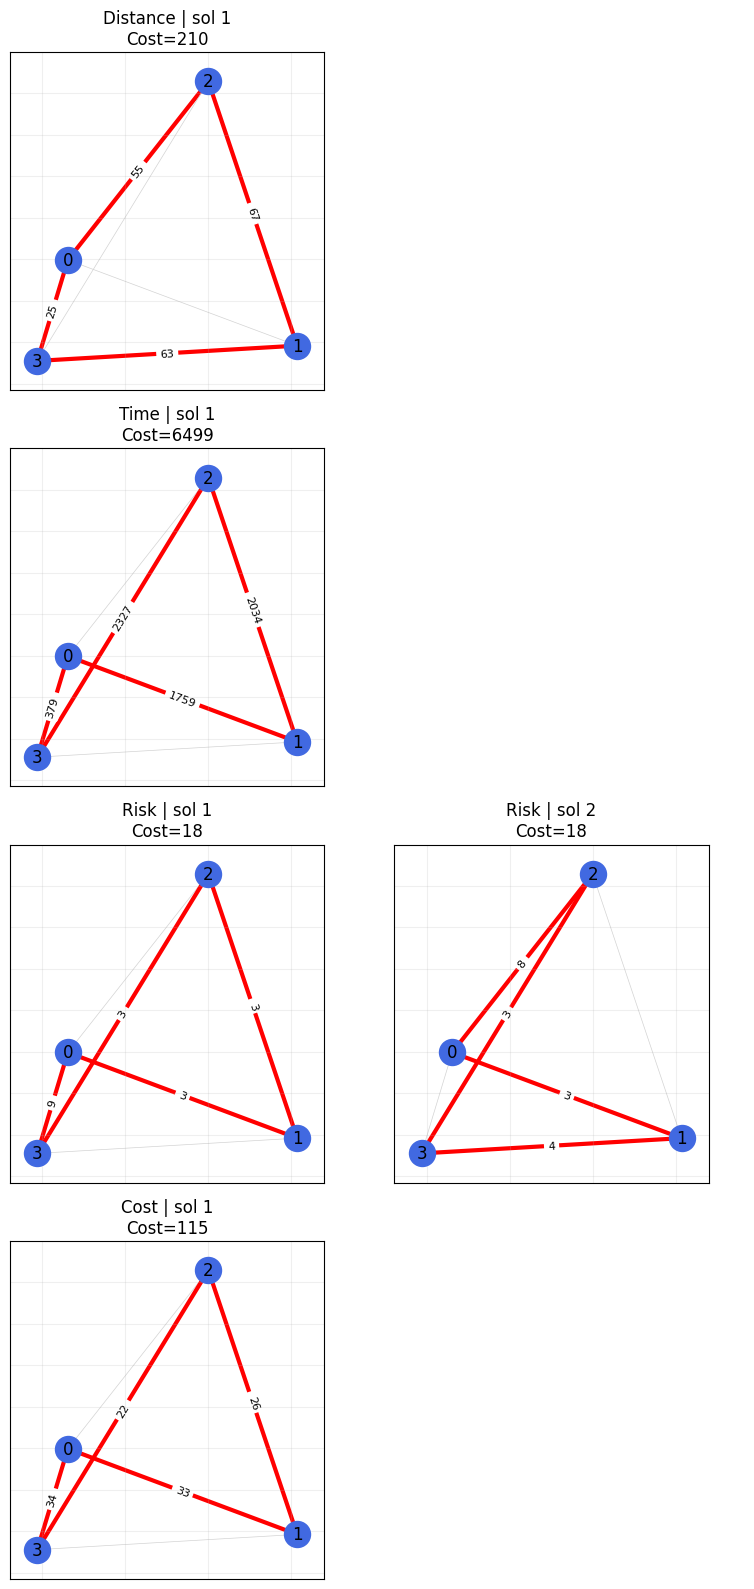

In [10]:
def visualize_tsp_solution(x, info, ax=None, title=""):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    coords = info["coords"]
    c = info["cost_matrix"]
    x_index = info["x_index"]

    route = decode_route(x, x_index)

    cost = sum(
        c[route[i], route[(i + 1) % len(route)]]
        for i in range(len(route))
    )

    G = nx.Graph()

    n = len(coords)

    for i in range(n):
        G.add_node(i, pos=coords[i])

    for i in range(n):
        for j in range(i + 1, n):
            G.add_edge(
                i,
                j,
                color="lightgray",
                width=0.5
            )

    edges_solution = [
        (route[i], route[(i + 1) % n])
        for i in range(n)
    ]

    for i, j in edges_solution:
        G[i][j]["color"] = "red"
        G[i][j]["width"] = 3

    pos = {i: coords[i] for i in range(n)}

    nx.draw_networkx_nodes(G, pos,
        				   node_color="royalblue", node_size=350,
                           ax=ax)

    nx.draw_networkx_labels(G, pos, ax=ax)

    nx.draw_networkx_edges(G, pos,
                           edge_color=[G[u][v]["color"] for u, v in G.edges()],
                           width=[G[u][v]["width"] for u, v in G.edges()],
                           ax=ax)

    nx.draw_networkx_edge_labels(G, pos,
                                 edge_labels={
                                     (i, j): int(c[i, j]) for i, j in edges_solution
                                 },
                                 font_size=8,
                                 ax=ax)

    ax.set_title(f"{title}\nCost={cost}")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)
    
def plot_all_solutions_grid(solutions, qubo_models):
    names = list(solutions.keys())

    n_rows = len(names)

    n_cols = max(len(solutions[name]["opt_x_list"]) for name in names)

    fig, axes = plt.subplots(n_rows, n_cols, 
                             figsize=(4 * n_cols, 4 * n_rows))

    if n_rows == 1 and n_cols == 1:
        axes = np.array([[axes]])
    elif n_rows == 1:
        axes = axes.reshape(1, -1)
    elif n_cols == 1:
        axes = axes.reshape(-1, 1)

    for i, name in enumerate(names):
        sols = solutions[name]["opt_x_list"]

        info = qubo_models[name]["info"]

        for j in range(n_cols):
            ax = axes[i, j]

            if j < len(sols):
                visualize_tsp_solution(
                    sols[j],
                    info,
                    ax=ax,
                    title=f"{name} | sol {j+1}"
                )
            else:
                ax.axis("off")

    plt.tight_layout()
    plt.show()


plot_all_solutions_grid(solutions, qubo_models)

# 7) QUBO to Max-Cut Reduction



We convert the QUBO problem

$$
\max_{x\in\{0,1\}^n} x^TQx
$$

into an equivalent Max-Cut problem on a graph with $n+1$ vertices.

An auxiliary vertex is introduced to absorb the linear terms generated during the QUBO-to-Ising transformation.

The Max-Cut adjacency matrix is defined as

$$
A_{ij}=-Q_{ij}
$$

and

$$
A_{i,n}=\sum_j Q_{ij}
$$

where the last vertex is the auxiliary node.

In [11]:
def normalize_qubo(Q):
    Q = np.array(Q, dtype=float)
    m = np.max(np.abs(Q))

    return Q / m if m > 0 else Q


def qubo_to_maxcut(Q):
    n = len(Q)

    A = np.zeros((n + 1, n + 1))
    for i in range(n):
        for j in range(i + 1, n):
            A[i, j] = A[j, i] = -Q[i, j]

    row_sums = Q.sum(axis=1)

    for i in range(n):
        A[i, n] = A[n, i] = row_sums[i]

    return A

maxcut_models = {}

for name, model in qubo_models.items():
    print(f"\nConverting: {name.upper()}")

    Q = model["Q"]
    Q = (Q + Q.T) / 2
    Q = normalize_qubo(-Q)

    A = qubo_to_maxcut(Q)
    
    maxcut_models[name] = {
        "Q": Q,
        "A": A
    }

    print("A shape:", A.shape)


Converting: DISTANCE
A shape: (17, 17)

Converting: TIME
A shape: (17, 17)

Converting: RISK
A shape: (17, 17)

Converting: COST
A shape: (17, 17)


# 8) Save Data


We export the Max-Cut adjacency matrices to JSON format.

In [12]:
import json
import os


def adjacency_matrix_to_json(A, filename):
    n = len(A)

    graph_data = {
        "directed": False,
        "multigraph": False,
        "graph": {},
        "nodes": [{"id": i} for i in range(n)],
        "links": [
            {
                "weight": float(A[i, j]),
                "source": i,
                "target": j
            }
            for i in range(n)
            for j in range(i + 1, n)
            if A[i, j] != 0
        ]
    }

    os.makedirs(os.path.dirname(filename), exist_ok=True)

    with open(filename, "w") as f:
        json.dump(graph_data, f, indent=2)

    print(f"Saved: {filename}")


base_path = "../qamoo/data/problems"

for idx, (name, model) in enumerate(maxcut_models.items()):
    A = model["A"]

    n_qubits = len(A)

    filename = (
        f"{base_path}/"
        f"{n_qubits}q/"
        f"problem_set_{n_qubits}q_10s_3o_{seed}/"
        f"problem_graph_{idx}.json"
    )

    adjacency_matrix_to_json(A, filename)

Saved: ../qamoo/data/problems/17q/problem_set_17q_10s_3o_2/problem_graph_0.json
Saved: ../qamoo/data/problems/17q/problem_set_17q_10s_3o_2/problem_graph_1.json
Saved: ../qamoo/data/problems/17q/problem_set_17q_10s_3o_2/problem_graph_2.json
Saved: ../qamoo/data/problems/17q/problem_set_17q_10s_3o_2/problem_graph_3.json


## 9) Save Auxiliary Metadata



We also store auxiliary metadata used during instance generation and QUBO construction.

This includes:

- variable indexing information
- coordinates
- penalty weights
- original graph instances

In [13]:
import pickle


base_path = (
    f"../qamoo/data/problems/"
    f"{n_vars+1}q/"
    f"problem_set_{n_vars+1}q_10s_3o_{seed}/"
)

os.makedirs(base_path, exist_ok=True)

with open(base_path + "problem_info.pkl", "wb") as f:
    pickle.dump(info, f)

with open(base_path + "graph_instances.pkl", "wb") as f:
    pickle.dump(instances, f)

print("Auxiliary metadata saved")

Auxiliary metadata saved


In [14]:
import json

def calculate_bounds(folder):
    """
    Calculates lower and upper bounds of weights for all graphs
    
    Args:
        folder: path to folder with problem_graph_X.json files
    
    Returns:
        lists of lower and upper bounds
    """
    lower_bounds = []
    upper_bounds = []
    
    for i in range(NUMBER_OF_GRAPHS):
        with open(f"{folder}/problem_graph_{i}.json") as f:
            data = json.load(f)
        
        # Sum positive and negative weights separately
        positive_weights = sum(l["weight"] for l in data["links"] if l["weight"] > 0)
        negative_weights = sum(l["weight"] for l in data["links"] if l["weight"] < 0)
        
        lower_bounds.append(negative_weights)
        upper_bounds.append(positive_weights)
    
    return lower_bounds, upper_bounds

NUMBER_OF_GRAPHS = 3

destination_folder = (
    f"../qamoo/data/problems/"
    f"{n_vars+1}q/"
    f"problem_set_{n_vars+1}q_10s_3o_{seed}/"
)

# Calculate and save bounds
lower, upper = calculate_bounds(destination_folder)

# Save to JSON files
with open(f"{destination_folder}/lower_bounds.json", "w") as f:
    json.dump(lower, f, indent=2)

with open(f"{destination_folder}/upper_bounds.json", "w") as f:
    json.dump(upper, f, indent=2)

print(f"Lower bounds (minimum values): {lower}")
print(f"Upper bounds (maximum values): {upper}")
print(f"\n✅ Bounds saved in: {destination_folder}")

Lower bounds (minimum values): [-32.088101265822786, -32.09017398508699, -32.06666666666666]
Upper bounds (maximum values): [24.04405063291138, 24.045086992543496, 24.033333333333328]

✅ Bounds saved in: ../qamoo/data/problems/17q/problem_set_17q_10s_3o_2/
